<a href="https://colab.research.google.com/github/ahmedelbtta6-archmed/ahmed/blob/main/first_project_data_scinence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

In [8]:
iris_data = datasets.load_iris()
features = iris_data.data
target = iris_data.target

In [9]:
df = pd.DataFrame(data = iris_data.data,
                  columns=iris_data.feature_names)
df['target'] = iris_data.target

In [10]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [11]:
# @title 🌸 Iris Dataset Explorer {display-mode: "form"}
import json
import pandas as pd
from IPython.display import HTML
from google.colab import output

def _report_js_error(message):
    print(f"JavaScript Error: {message}")

output.register_callback('report_js_error', _report_js_error)

# Prepare data for JS
# Mapping target numbers to names for the UI
target_names = ['Setosa', 'Versicolor', 'Virginica']
dashboard_df = df.copy()
dashboard_df['species'] = dashboard_df['target'].map(lambda x: target_names[int(x)])

json_data = dashboard_df.to_json(orient='records')

html_content = """
<!DOCTYPE html>
<html lang='en'>
<head>
    <meta charset='UTF-8'>
    <script src='https://cdn.jsdelivr.net/npm/chart.js'></script>
    <style>
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; color: #333; }
        .dashboard-container { max-width: 1200px; margin: 0 auto; display: flex; flex-direction: column; gap: 20px; }
        .kpi-row { display: grid; grid-template-columns: repeat(auto-fit, minmax(200px, 1fr)); gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 12px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); }
        .kpi-card { text-align: center; }
        .kpi-value { font-size: 24px; font-weight: bold; color: #4a90e2; margin: 10px 0; }
        .kpi-label { font-size: 14px; color: #777; text-transform: uppercase; }
        .middle-row { display: grid; grid-template-columns: 2fr 1fr; gap: 20px; }
        .bottom-row { display: grid; grid-template-columns: 1fr; gap: 20px; }
        .chart-container { display: flex; flex-direction: column; height: 400px; }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 0; }
        h2 { margin-top: 0; font-size: 18px; color: #444; }
        @media (max-width: 768px) { .middle-row { grid-template-columns: 1fr; } }
    </style>
</head>
<body>
    <div class='dashboard-container'>
        <div class='kpi-row'>
            <div class='card kpi-card'>
                <div class='kpi-label'>Total Samples</div>
                <div class='kpi-value' id='total-samples'>0</div>
            </div>
            <div class='card kpi-card'>
                <div class='kpi-label'>Avg Sepal Length</div>
                <div class='kpi-value' id='avg-sepal'>0.0</div>
            </div>
            <div class='card kpi-card'>
                <div class='kpi-label'>Avg Petal Length</div>
                <div class='kpi-value' id='avg-petal'>0.0</div>
            </div>
            <div class='card kpi-card'>
                <div class='kpi-label'>Species Count</div>
                <div class='kpi-value'>3</div>
            </div>
        </div>

        <div class='middle-row'>
            <div class='card chart-container'>
                <h2>Feature Distribution by Species</h2>
                <div class='canvas-wrapper'>
                    <canvas id='mainBarChart'></canvas>
                </div>
            </div>
            <div class='card chart-container'>
                <h2>Species Distribution</h2>
                <div class='canvas-wrapper'>
                    <canvas id='speciesPieChart'></canvas>
                </div>
            </div>
        </div>

        <div class='bottom-row'>
            <div class='card chart-container'>
                <h2>Petal Length vs Width Scatter</h2>
                <div class='canvas-wrapper'>
                    <canvas id='scatterChart'></canvas>
                </div>
            </div>
        </div>
    </div>

    <script>
        window.onerror = function(message) {
            google.colab.kernel.invokeFunction('report_js_error', [message], {});
        };

        const rawData = DATA_PLACEHOLDER;

        function initDashboard() {
            // KPIs
            document.getElementById('total-samples').innerText = rawData.length;
            const avgSepal = rawData.reduce((acc, row) => acc + row['sepal length (cm)'], 0) / rawData.length;
            const avgPetal = rawData.reduce((acc, row) => acc + row['petal length (cm)'], 0) / rawData.length;
            document.getElementById('avg-sepal').innerText = avgSepal.toFixed(2) + ' cm';
            document.getElementById('avg-petal').innerText = avgPetal.toFixed(2) + ' cm';

            // Data Processing for Charts
            const speciesGrouped = {};
            rawData.forEach(row => {
                if (!speciesGrouped[row.species]) speciesGrouped[row.species] = [];
                speciesGrouped[row.species].push(row);
            });

            const speciesLabels = Object.keys(speciesGrouped);

            // Bar Chart: Avg measurements
            const barCtx = document.getElementById('mainBarChart').getContext('2d');
            new Chart(barCtx, {
                type: 'bar',
                data: {
                    labels: speciesLabels,
                    datasets: [{
                        label: 'Avg Sepal Length',
                        data: speciesLabels.map(s => speciesGrouped[s].reduce((a,b) => a + b['sepal length (cm)'], 0) / speciesGrouped[s].length),
                        backgroundColor: '#4a90e2'
                    }, {
                        label: 'Avg Petal Length',
                        data: speciesLabels.map(s => speciesGrouped[s].reduce((a,b) => a + b['petal length (cm)'], 0) / speciesGrouped[s].length),
                        backgroundColor: '#50e3c2'
                    }]
                },
                options: { responsive: true, maintainAspectRatio: false }
            });

            // Pie Chart
            const pieCtx = document.getElementById('speciesPieChart').getContext('2d');
            new Chart(pieCtx, {
                type: 'doughnut',
                data: {
                    labels: speciesLabels,
                    datasets: [{
                        data: speciesLabels.map(s => speciesGrouped[s].length),
                        backgroundColor: ['#ff6384', '#36a2eb', '#cc65fe']
                    }]
                },
                options: { responsive: true, maintainAspectRatio: false }
            });

            // Scatter Plot
            const scatterCtx = document.getElementById('scatterChart').getContext('2d');
            const colors = { 'Setosa': '#ff6384', 'Versicolor': '#36a2eb', 'Virginica': '#cc65fe' };
            new Chart(scatterCtx, {
                type: 'scatter',
                data: {
                    datasets: speciesLabels.map(s => ({
                        label: s,
                        data: speciesGrouped[s].map(row => ({ x: row['petal length (cm)'], y: row['petal width (cm)'] })),
                        backgroundColor: colors[s]
                    }))
                },
                options: {
                    responsive: true,
                    maintainAspectRatio: false,
                    scales: { x: { title: { display: true, text: 'Petal Length (cm)' } }, y: { title: { display: true, text: 'Petal Width (cm)' } } }
                }
            });
        }

        initDashboard();
    </script>
</body>
</html>
"""

HTML(html_content.replace('DATA_PLACEHOLDER', json_data))


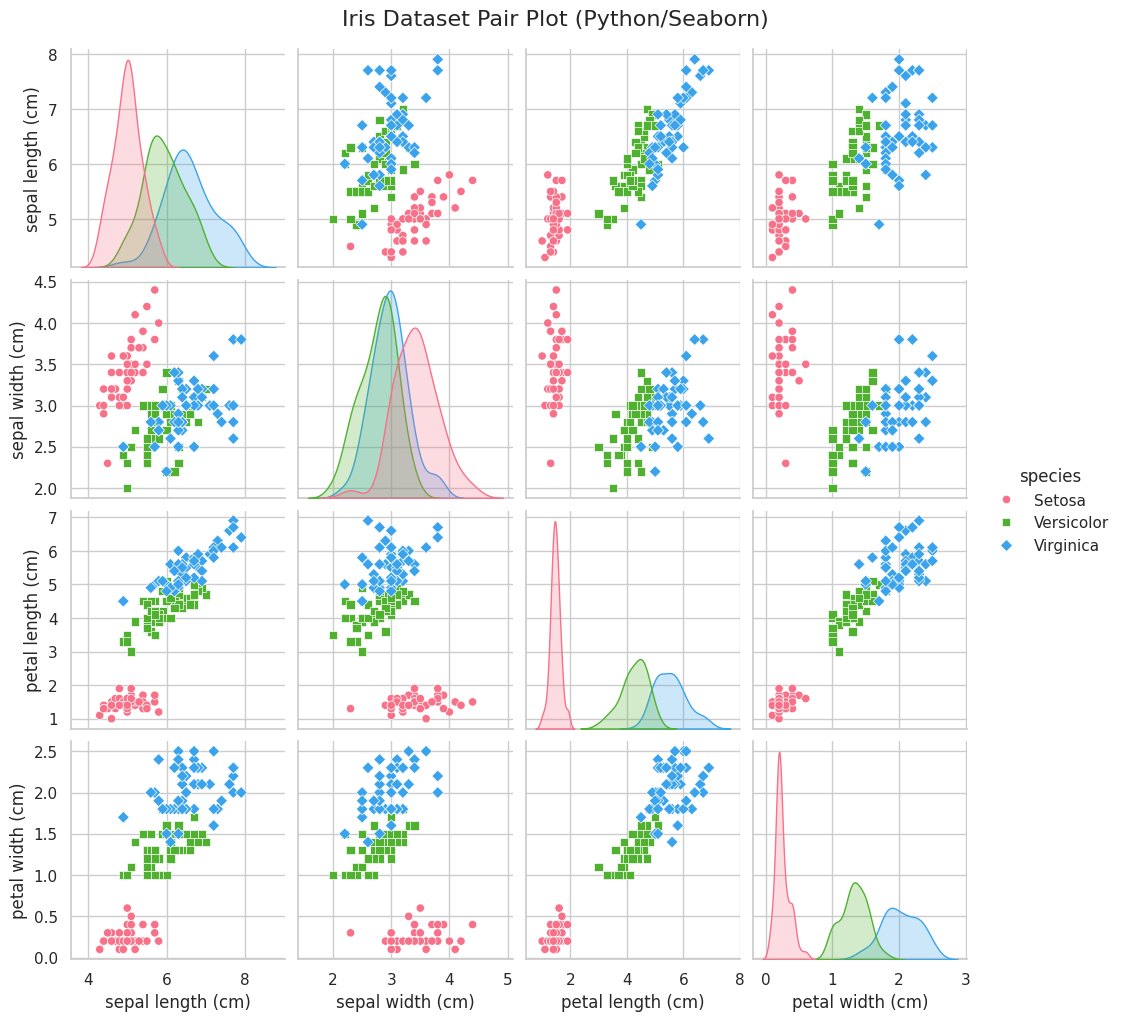

/tmp/ipykernel_1048/1044099065.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[row, col], x='species', y=feature, data=plot_df, palette="Set2")
/tmp/ipykernel_1048/1044099065.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[row, col], x='species', y=feature, data=plot_df, palette="Set2")
/tmp/ipykernel_1048/1044099065.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[row, col], x='species', y=feature, data=plot_df, palette="Set2")
/tmp/ipykernel_1048/1044099065.py:23: FutureWarning: 

Passing `palette` wit

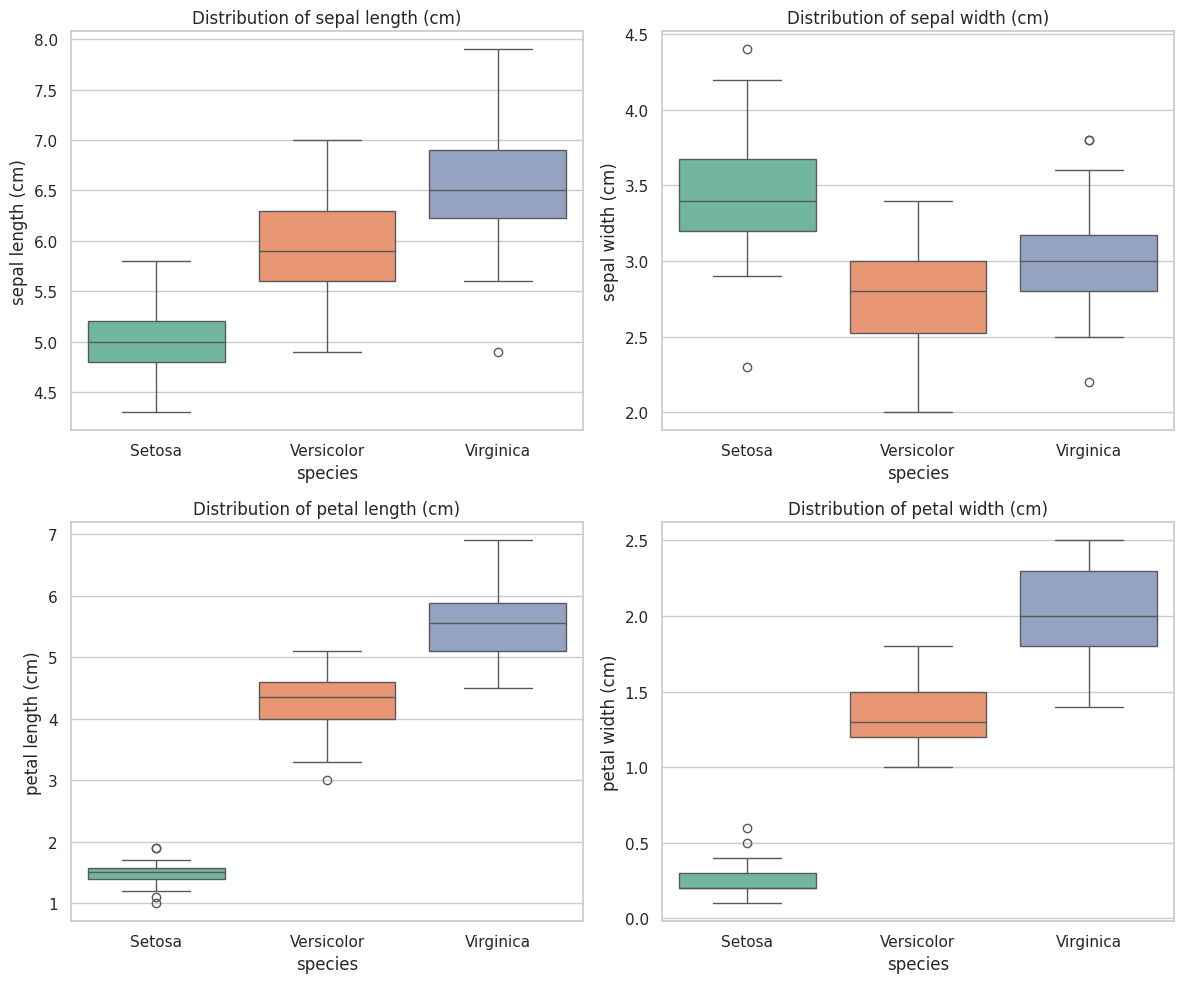

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the data for plotting
plot_df = df.copy()
target_names = ['Setosa', 'Versicolor', 'Virginica']
plot_df['species'] = plot_df['target'].map(lambda x: target_names[int(x)])

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# 1. Pair Plot: To see relationships between all features
g = sns.pairplot(plot_df.drop('target', axis=1), hue="species", palette="husl", markers=["o", "s", "D"])
g.fig.suptitle("Iris Dataset Pair Plot (Python/Seaborn)", y=1.02, fontsize=16)
plt.show()

# 2. Box Plots: To see distributions and outliers for each feature
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = iris_data.feature_names

for i, feature in enumerate(features):
    row, col = i // 2, i % 2
    sns.boxplot(ax=axes[row, col], x='species', y=feature, data=plot_df, palette="Set2")
    axes[row, col].set_title(f'Distribution of {feature}')

plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix
# محللين البيانات بيستخدموا الـ correlation عشان يعرفوا انهي صفات مرتبطة ببعض
corr = df.drop('target', axis=1).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap (Data Analysis Standard)')
plt.show()